# Random partitions

## Chinese restaurant process

Cluster assignment:
[0, 1, 0, 0, 0, 1, 2, 1, 1, 1, 3, 2, 0, 3, 0, 2, 0, 3, 1, 0, 1, 0, 0, 1, 1, 1, 1, 4, 5, 1]

Cluster sizes:
[10 12  3  3  1  1]

Number of clusters:
6


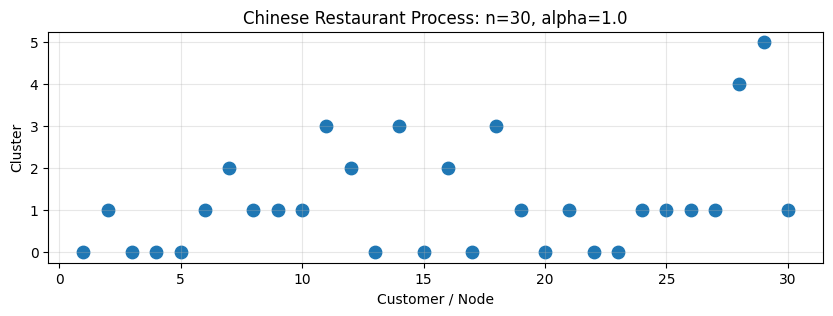

In [2]:
import numpy as np
import matplotlib.pyplot as plt


def chinese_restaurant_process(n, alpha, seed=None):
    """
    Simulate a partition using the Chinese Restaurant Process (CRP).

    Parameters
    ----------
    n : int
        Number of customers/nodes.
    alpha : float
        Concentration parameter controlling the creation of new clusters.
    seed : int or None
        Random seed for reproducibility.

    Returns
    -------
    assignments : list
        Cluster assignment for each customer.
    """

    rng = np.random.default_rng(seed)

    # The first customer always creates the first cluster.
    assignments = [0]

    # Store the current size of each cluster.
    cluster_sizes = [1]

    # Add customers one by one.
    for i in range(1, n):

        # Total probability mass is i + alpha.
        total_mass = i + alpha

        # Existing clusters receive probability proportional to size.
        existing_weights = np.array(cluster_sizes, dtype=float)

        # A new cluster receives weight alpha.
        weights = np.append(existing_weights, alpha)

        # Convert weights into probabilities.
        probabilities = weights / total_mass

        # Sample an existing cluster or create a new one.
        chosen_cluster = rng.choice(
            len(probabilities),
            p=probabilities
        )

        # If the new-cluster option was selected...
        if chosen_cluster == len(cluster_sizes):

            # Create a new cluster with one customer.
            cluster_sizes.append(1)

            # Store its cluster label.
            assignments.append(chosen_cluster)

        else:

            # Add the customer to the selected cluster.
            cluster_sizes[chosen_cluster] += 1

            # Store its cluster label.
            assignments.append(chosen_cluster)

    return assignments


# ---------------------------------------------------------
# Example: simulate one CRP realization
# ---------------------------------------------------------

n = 30
alpha = 1.0

assignments = chinese_restaurant_process(
    n=n,
    alpha=alpha,
    seed=0
)

print("Cluster assignment:")
print(assignments)


# ---------------------------------------------------------
# Convert assignments into cluster sizes
# ---------------------------------------------------------

cluster_sizes = np.bincount(assignments)

print("\nCluster sizes:")
print(cluster_sizes)

print("\nNumber of clusters:")
print(len(cluster_sizes))


# ---------------------------------------------------------
# Visualize the partition
# ---------------------------------------------------------

plt.figure(figsize=(10, 3))

# Each point represents one customer/node.
plt.scatter(
    range(1, n + 1),
    assignments,
    s=80
)

plt.xlabel("Customer / Node")
plt.ylabel("Cluster")
plt.title(f"Chinese Restaurant Process: n={n}, alpha={alpha}")

plt.yticks(range(len(cluster_sizes)))

plt.grid(alpha=0.3)
plt.show()

In [3]:
# Compare different values of alpha

n = 100
alphas = [0.1, 1, 5, 20]

for alpha in alphas:

    assignments = chinese_restaurant_process(
        n=n,
        alpha=alpha,
        seed=123
    )

    number_of_clusters = len(set(assignments))

    print(
        f"alpha = {alpha:4.1f} "
        f"-> number of clusters = {number_of_clusters}"
    )

alpha =  0.1 -> number of clusters = 1
alpha =  1.0 -> number of clusters = 3
alpha =  5.0 -> number of clusters = 13
alpha = 20.0 -> number of clusters = 34


## Pitman-Yor process

## Gnedin process

##  Kolchin Partition Models

## Allelic partition